# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"

print("Ready")

Ready


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [2]:
# GIVEN: load the data
df = pd.read_csv("data/Wholesale customers data.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [3]:
# TODO: explore the data
# Hint: df.shape, df.info(), and df[spend_cols].describe()

print(df.shape)
print()
df.info()
print()
df[spend_cols].describe()


(440, 8)

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB



,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [4]:
# TODO: build X from the spend columns and scale it
# Hint: X = df[spend_cols].values
# Hint: Xs = StandardScaler().fit_transform(X)

X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

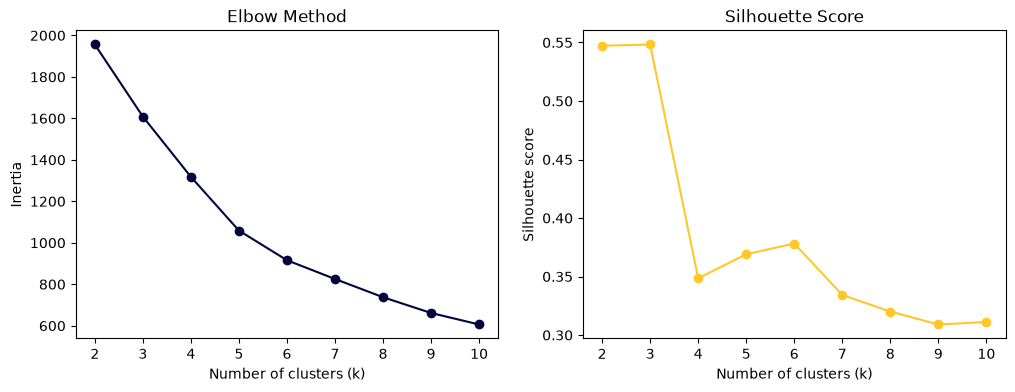

2 0.547
3 0.548
4 0.348
5 0.369
6 0.378
7 0.334
8 0.32
9 0.309
10 0.311


In [5]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o", color="#00053E")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia")

ax[1].plot(ks, sils, marker="o", color="#FFC72C")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette score")
plt.show()

for k, s in zip(ks, sils):
    print(k, round(s, 3))


**Your chosen k and why:**

I chose K = 3. The silhouette score was highest at k=3 (0.548, just above 0.54 at k=2) and dropped very sharply for k=4 and above, meaning three clusters are the best seperated. The elbow plot had no sharp bend, only a gradual flattening, so I relied mainly on the silhouette score, and three segments are also more useful to a distributor than two.

## Step 5: Fit k-means with your chosen k

In [6]:
# TODO: fit KMeans at your chosen k and attach the labels to df
# Hint: kmeans = KMeans(n_clusters=YOUR_K, random_state=42, n_init=10).fit(Xs)
# Hint: df["cluster"] = kmeans.labels_

# Step 5
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_

## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

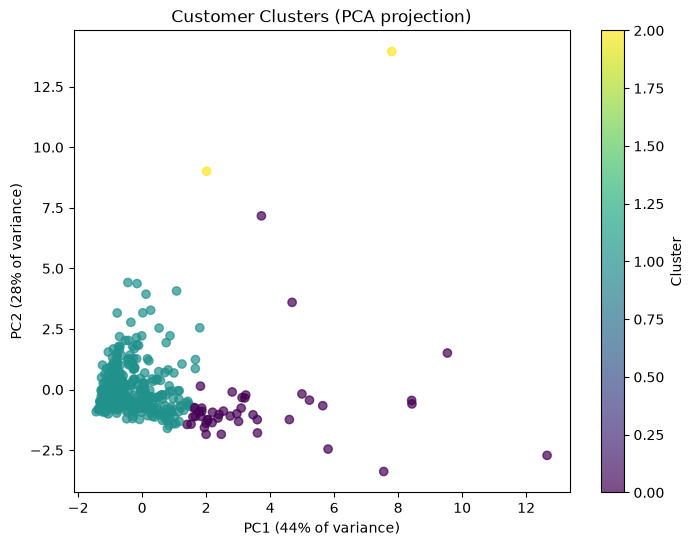

In [7]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
# Hint: pcs = PCA(n_components=2).fit_transform(Xs)
# Hint: plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])

# Step 6
pca = PCA(n_components=2)
pcs = pca.fit_transform(Xs)

plt.figure(figsize=(8, 6))
plt.scatter(pcs[:, 0], pcs[:, 1], c=df["cluster"], cmap="viridis", alpha=0.7)
plt.title("Customer Clusters (PCA projection)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.colorbar(label="Cluster")
plt.show()


## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [8]:
# TODO: build a profile table of per-cluster averages
# Hint: df.groupby("cluster")[spend_cols].mean().round(0)
# Hint: df["cluster"].value_counts() for the sizes

# Step 7
print(df["cluster"].value_counts().sort_index())
print()
print(df.groupby("cluster")[spend_cols].mean().round(0))
print()
print(pd.crosstab(df["cluster"], df["Channel"]))


cluster
0     45
1    393
2      2
Name: count, dtype: int64

           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
cluster                                                                  
0        10441.0  19386.0  28656.0   2190.0           13328.0      2374.0
1        12063.0   4115.0   5535.0   2941.0            1696.0      1299.0
2        34782.0  30367.0  16898.0  48702.0             756.0     26776.0

Channel    1   2
cluster         
0          1  44
1        295  98
2          2   0


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)

I chose k = 3. The silhouette score was highest at k = 3 (0.548, just above 0.547 at k = 2) and dropped sharply to 0.348 at k = 4, so three clusters are the best separated. The elbow plot had no sharp bend, only a gradual flattening after about k = 5, so I relied mainly on the silhouette score. Three segments are also more useful to a distributor than two.

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?

- Cluster 0 (45 customers): Grocery and household-goods buyers, mostly retailers. They spend far more than the other groups on Grocery (28,700), Milk (19,400) and Detergents_Paper (13,300), and relatively little on Fresh and Frozen. 44 of the 45 are Retail channel,, so these look like stores that stock shelves.

- Cluster 1 (393 customers): the typical mid-size customer, mostly restaurants and hotels.** Their spending is moderate across the board, with Fresh (~12,100) as their biggest category and low spending on Milk, Grocery and Detergents_Paper. 295 of the 393 are Horeca (restaurant, hotel and cafe), though 98 are retail. This is almost 90% of all customers.

- Cluster 2 (2 customers):  very large Horeca accounts.** They spend heavily on everything except Detergents_Paper, including Frozen (~48,700), Fresh (~34,800), Milk (~30,400) and Delicassen (~26,800). Both are Horeca. With only two customers, this is really an outlier group of the biggest buyers.

3. **One action per segment:** what should the distributor do differently for each group?

Cluster 0:Offer bulk discounts and standing orders on grocery, dairy and cleaning products, since these customers already buy them in volume and are mostly retailers.

Cluster 1: Focus on fresh-food delivery reliability and a loyalty program, because it is the largest group and spends mainly on Fresh. Cross-sell Milk and Grocery, where they currently spend little

Cluster 2:Assign a dedicated account manager and negotiate volume contracts. Losing either customer would remove a large share of revenue.

4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?

The spending data is heavily skewed, and k-means is sensitive to outliers. Cluster 2 has only 2 customers, so the model mostly separated a few extreme spenders from everyone else, and cluster 1 absorbed almost 90% of the data. That is also probably why the silhouette score was highest at small k. A next step would be to apply a log transform to the spend columns or remove the extreme outliers, then re-run the clustering to see whether more balanced segments appear. I would also compare k = 5 or 6 and check whether the segments line up with Region, which I did not cluster on.
## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing